In [1]:
import pandas as pd

raw = pd.read_csv("bank-additional.csv", sep=";")

assert raw.shape == (4_119, 21), raw.shape
assert set(raw["y"].unique()) == {"no", "yes"}

X = raw.drop(columns=["y", "duration"])
y = raw["y"].map({"no": 0, "yes": 1})

print(f"Ham veri boyutu: {raw.shape}")
print(f"Model girdi sayısı: {X.shape[1]}")
print(f"Birebir kopya ham kayıt: {raw.duplicated().sum()}")
print(f"Tekrarlanan model girdisi: {X.duplicated().sum()}")

Ham veri boyutu: (4119, 21)
Model girdi sayısı: 19
Birebir kopya ham kayıt: 0
Tekrarlanan model girdisi: 20


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

# Yönergedeki temel seed ve ondan türetilen alt seed'ler
BASE_SEED = 29034 + 2026
seed_names = (
    "python", "numpy", "torch", "holdout", "outer_cv",
    "inner_cv", "early_stop", "random_search", "bootstrap",
)
seed_values = np.random.SeedSequence(BASE_SEED).generate_state(len(seed_names))
SEEDS = dict(zip(seed_names, map(int, seed_values)))

# Model girdileri aynı olan satırlara aynı grup numarası ver.
groups = X.groupby(list(X.columns), dropna=False, sort=False).ngroup()

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEEDS["holdout"],
)

# Test büyüklüğüne en yakın katı seç.
# Eşitlikte hedef pozitif sınıf sayısına yakınlığı kullan.
target_test_size = int(np.ceil(len(y) * 0.20))
target_test_positives = round(target_test_size * y.mean())

def split_distance(split):
    _, candidate_test = split
    return (
        abs(len(candidate_test) - target_test_size),
        abs(int(y.iloc[candidate_test].sum()) - target_test_positives),
    )

dev_idx, test_idx = min(splitter.split(X, y, groups), key=split_distance)

assert len(dev_idx) + len(test_idx) == len(raw)
assert set(dev_idx).isdisjoint(test_idx)
assert set(groups.iloc[dev_idx]).isdisjoint(groups.iloc[test_idx])

# EDA için yalnızca development verisini hazırla.
X_dev = X.iloc[dev_idx].copy()
y_dev = y.iloc[dev_idx].copy()

# Orijinal satır indekslerini ve küme bazındaki sınıf oranlarını kaydet.
split_table = pd.DataFrame({
    "row_id": raw.index,
    "split": "development",
})
split_table.loc[test_idx, "split"] = "independent_test"

for split_name, indices in [
    ("development", dev_idx),
    ("independent_test", test_idx),
]:
    mask = split_table["split"].eq(split_name)
    positive_rate = y.iloc[indices].mean()
    split_table.loc[mask, "positive_rate"] = positive_rate
    split_table.loc[mask, "negative_rate"] = 1 - positive_rate

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
split_table.to_csv(results_dir / "dataset_split.csv", index=False)

summary = split_table.groupby("split").agg(
    satir_sayisi=("row_id", "size"),
    pozitif_oran=("positive_rate", "first"),
    negatif_oran=("negative_rate", "first"),
)

print("Temel seed:", BASE_SEED)
print(summary.round(4).to_string())
print("\nKaydedildi: results/dataset_split.csv")

Temel seed: 31060
                  satir_sayisi  pozitif_oran  negatif_oran
split                                                     
development               3296        0.1089        0.8911
independent_test           823        0.1118        0.8882

Kaydedildi: results/dataset_split.csv


Development: 3296 satır, 19 model girdisi
Sayısal: 9 | Kategorik: 10


,dtype,unique_values,missing_values,unknown_values
feature,,,,
age,int64,64,0,0
job,object,12,0,31
marital,object,4,0,11
education,object,7,0,136
default,object,3,0,639
housing,object,3,0,84
loan,object,3,0,84
contact,object,2,0,0
month,object,10,0,0


,check,count,percent
0,Birebir kopya ham kayıt,0,0.00
1,Tekrarlanan model girdisi,16,0.49
2,pdays = 999,3174,96.30


,count,percent
class,,
no,2937,89.11
yes,359,10.89


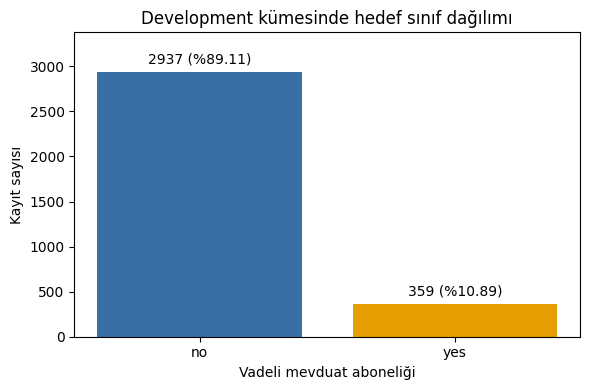

In [3]:
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

eda_results_dir = Path("results/eda")
eda_figures_dir = Path("figures/eda")
eda_results_dir.mkdir(parents=True, exist_ok=True)
eda_figures_dir.mkdir(parents=True, exist_ok=True)

# Sütun tipleri ve veri kalitesi
numeric_columns = X_dev.select_dtypes(include="number").columns.tolist()
categorical_columns = X_dev.columns.difference(numeric_columns, sort=False).tolist()

feature_profile = pd.DataFrame({
    "dtype": X_dev.dtypes.astype(str),
    "unique_values": X_dev.nunique(dropna=True),
    "missing_values": X_dev.isna().sum(),
    "unknown_values": X_dev.eq("unknown").sum(),
})
feature_profile.index.name = "feature"

special_values = pd.DataFrame({
    "check": [
        "Birebir kopya ham kayıt",
        "Tekrarlanan model girdisi",
        "pdays = 999",
    ],
    "count": [
        raw.loc[X_dev.index].duplicated().sum(),
        X_dev.duplicated().sum(),
        X_dev["pdays"].eq(999).sum(),
    ],
})
special_values["percent"] = 100 * special_values["count"] / len(X_dev)

# Hedef sınıf sayıları ve yüzdeleri
class_distribution = (
    y_dev.value_counts()
    .reindex([0, 1], fill_value=0)
    .rename(index={0: "no", 1: "yes"})
    .rename("count")
    .to_frame()
)
class_distribution.index.name = "class"
class_distribution["percent"] = 100 * class_distribution["count"] / len(y_dev)

feature_profile.to_csv(eda_results_dir / "feature_profile.csv")
special_values.to_csv(eda_results_dir / "special_values.csv", index=False)
class_distribution.to_csv(eda_results_dir / "class_distribution.csv")

print(f"Development: {len(X_dev)} satır, {X_dev.shape[1]} model girdisi")
print(f"Sayısal: {len(numeric_columns)} | Kategorik: {len(categorical_columns)}")
display(feature_profile)
display(special_values.round(2))
display(class_distribution.round(2))

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(class_distribution.index, class_distribution["count"],
              color=["#386FA4", "#E69F00"])
labels = [
    f"{count} (%{percent:.2f})"
    for count, percent in zip(
        class_distribution["count"], class_distribution["percent"]
    )
]
ax.bar_label(bars, labels=labels, padding=4)
ax.set_ylim(0, class_distribution["count"].max() * 1.15)
ax.set(title="Development kümesinde hedef sınıf dağılımı",
       xlabel="Vadeli mevduat aboneliği", ylabel="Kayıt sayısı")
fig.tight_layout()
fig.savefig(eda_figures_dir / "class_distribution.png", dpi=180)
plt.show()

,n,mean,median,std,q1,q3,iqr,min,max
feature,,,,,,,,,
age,3296,40.150,38.000,10.296,32.000,47.000,15.000,18.000,86.000
campaign,3296,2.524,2.000,2.529,1.000,3.000,2.000,1.000,29.000
pdays,122,5.770,5.500,3.715,3.000,6.750,3.750,0.000,21.000
previous,3296,0.185,0.000,0.529,0.000,0.000,0.000,0.000,6.000
emp.var.rate,3296,0.096,1.100,1.558,-1.800,1.400,3.200,-3.400,1.400
cons.price.idx,3296,93.580,93.444,0.578,93.075,93.994,0.919,92.201,94.767
cons.conf.idx,3296,-40.482,-41.800,4.582,-42.700,-36.400,6.300,-50.800,-26.900
euribor3m,3296,3.636,4.857,1.727,1.334,4.961,3.627,0.635,5.045
nr.employed,3296,5167.201,5191.000,73.255,5099.100,5228.100,129.000,4963.600,5228.100


,lower_bound,upper_bound,flagged_count,flagged_percent,zero_iqr
feature,,,,,
age,9.500,69.500,32,0.971,False
campaign,-2.000,6.000,186,5.643,False
pdays,-2.625,12.375,6,4.918,False
previous,0.000,0.000,466,14.138,True
emp.var.rate,-6.600,6.200,0,0.000,False
cons.price.idx,91.697,95.372,0,0.000,False
cons.conf.idx,-52.150,-26.950,35,1.062,False
euribor3m,-4.107,10.402,0,0.000,False
nr.employed,4905.600,5421.600,0,0.000,False


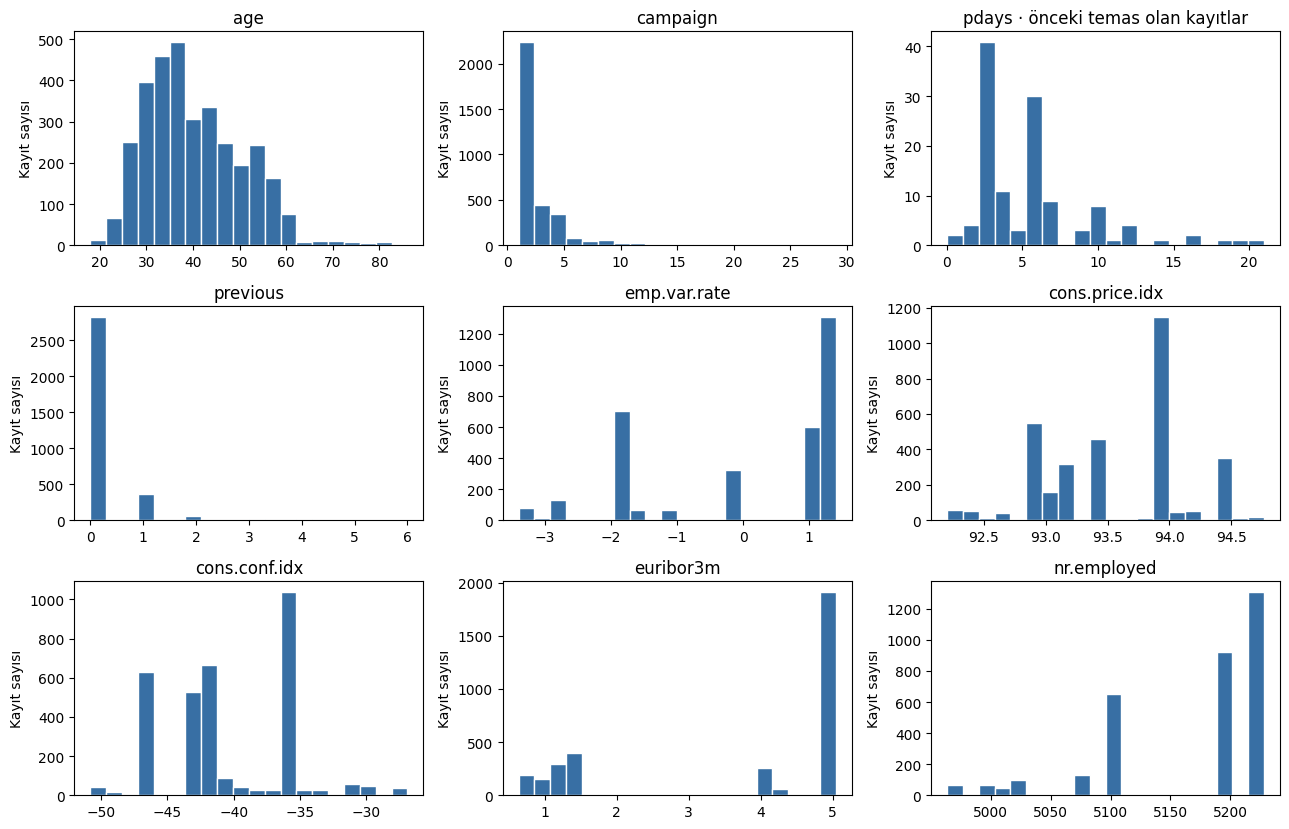

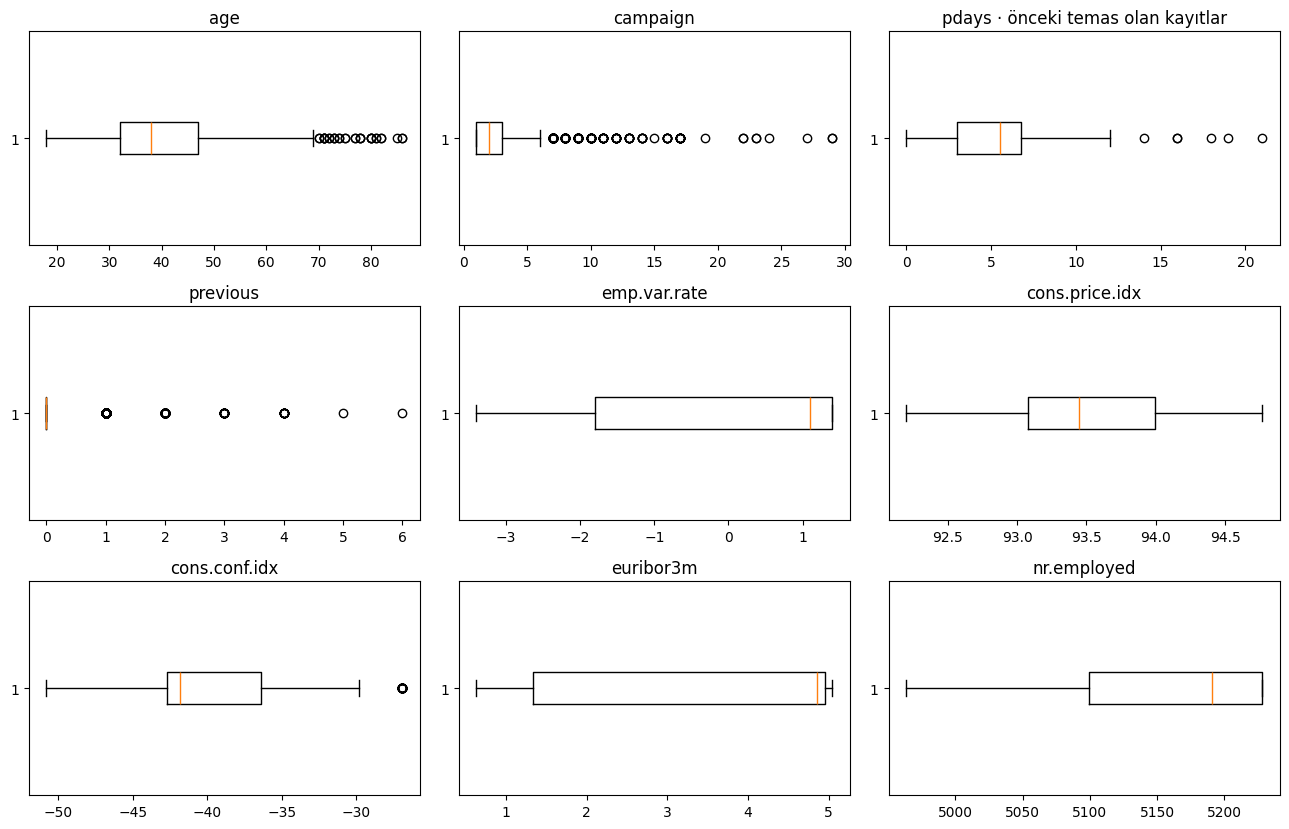

In [4]:
import math

numeric_data = X_dev[numeric_columns].copy()
numeric_data["pdays"] = numeric_data["pdays"].mask(
    numeric_data["pdays"].eq(999)
)

# Tanımlayıcı istatistikler
stats = numeric_data.describe().T
stats = stats.rename(columns={
    "count": "n",
    "25%": "q1",
    "50%": "median",
    "75%": "q3",
})
stats["n"] = stats["n"].astype(int)
stats["iqr"] = stats["q3"] - stats["q1"]
stats = stats[["n", "mean", "median", "std", "q1", "q3", "iqr", "min", "max"]]

# IQR sınırları ve sınır dışında kalan gözlem sayısı
bounds = pd.DataFrame({
    "lower_bound": stats["q1"] - 1.5 * stats["iqr"],
    "upper_bound": stats["q3"] + 1.5 * stats["iqr"],
})
outside = (
    numeric_data.lt(bounds["lower_bound"], axis="columns")
    | numeric_data.gt(bounds["upper_bound"], axis="columns")
)

outlier_summary = bounds.copy()
outlier_summary["flagged_count"] = outside.sum()
outlier_summary["flagged_percent"] = (
    100 * outlier_summary["flagged_count"] / stats["n"]
)
outlier_summary["zero_iqr"] = stats["iqr"].eq(0)

stats.to_csv(eda_results_dir / "numeric_summary.csv", index_label="feature")
outlier_summary.to_csv(
    eda_results_dir / "iqr_outlier_summary.csv", index_label="feature"
)

display(stats.round(3))
display(outlier_summary.round(3))

# Histogramlar ve kutu grafikleri
ncols = 3
nrows = math.ceil(len(numeric_columns) / ncols)

for plot_type in ("histograms", "boxplots"):
    fig, axes = plt.subplots(
        nrows, ncols, figsize=(13, 2.8 * nrows), squeeze=False
    )
    for ax, column in zip(axes.flat, numeric_columns):
        values = numeric_data[column].dropna()

        if plot_type == "histograms":
            ax.hist(values, bins=20, color="#386FA4", edgecolor="white")
            ax.set_ylabel("Kayıt sayısı")
        else:
            ax.boxplot(values, vert=False)

        title = "pdays · önceki temas olan kayıtlar" if column == "pdays" else column
        ax.set_title(title)

    for ax in list(axes.flat)[len(numeric_columns):]:
        ax.set_visible(False)

    fig.tight_layout()
    fig.savefig(eda_figures_dir / f"numeric_{plot_type}.png", dpi=180)
    plt.show()

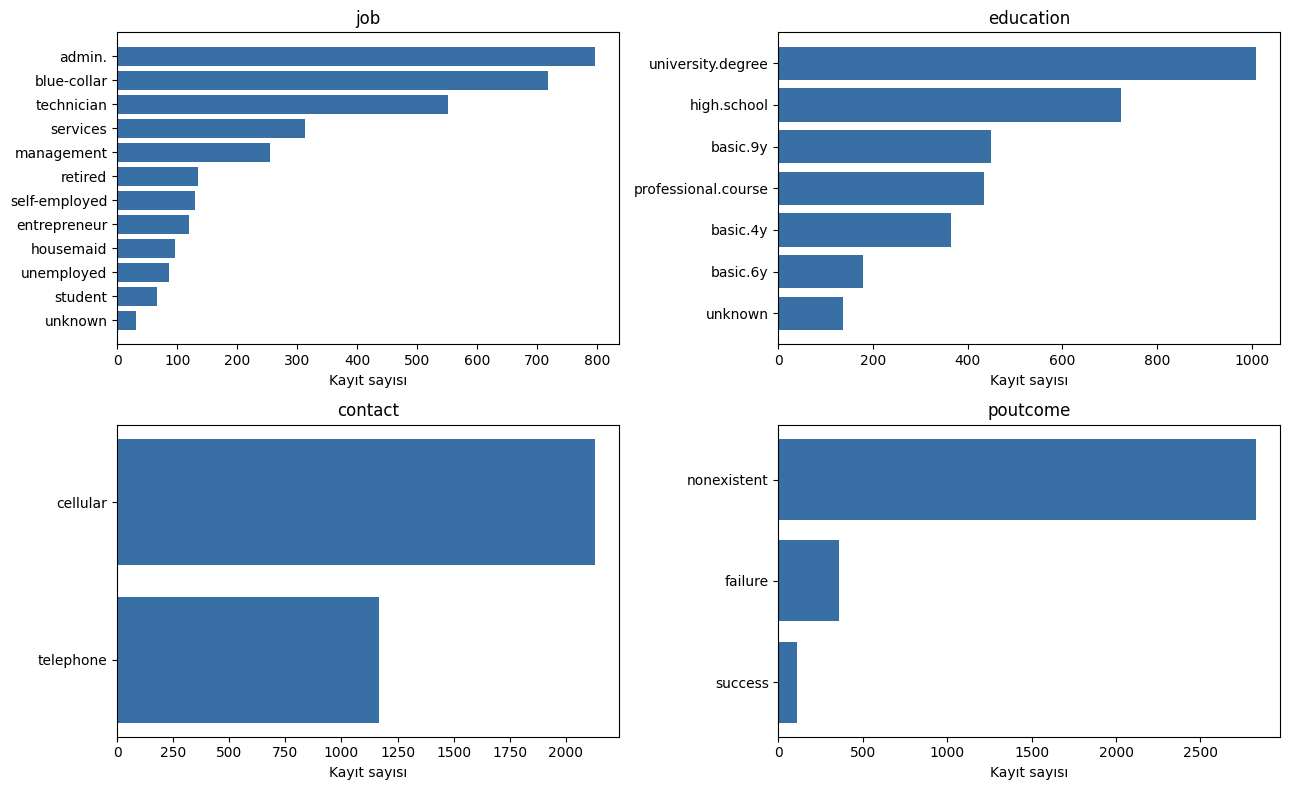

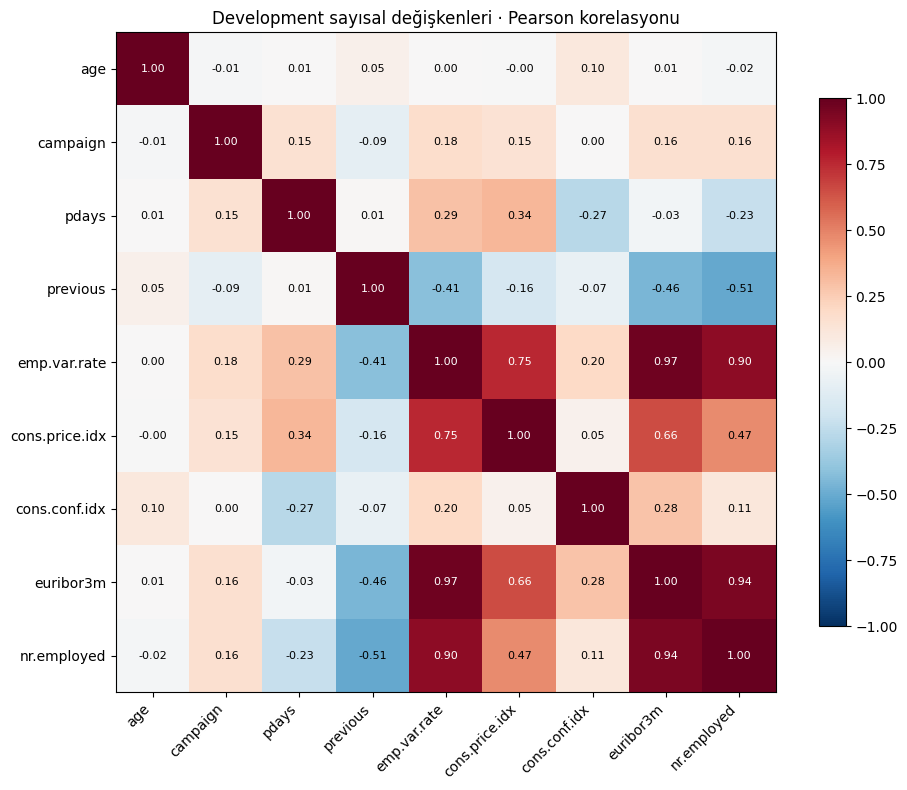

feature   age               campaign              previous              pdays  \
        count   mean median    count  mean median    count  mean median count   
y                                                                               
no       2937  39.90   38.0     2937  2.59    2.0     2937  0.14    0.0    44   
yes       359  42.18   39.0      359  1.97    2.0      359  0.55    0.0    78   

feature              euribor3m               
         mean median     count  mean median  
y                                            
no       6.41    6.0      2937  3.82   4.86  
yes      5.41    4.5       359  2.11   1.26

,feature,category,count,positive_count,positive_percent
32,contact,cellular,2130,297,13.94
33,contact,telephone,1166,62,5.32
49,poutcome,nonexistent,2830,238,8.41
50,poutcome,failure,356,48,13.48
51,poutcome,success,110,73,66.36


In [5]:
# 1. Tüm kategorik sütunlar için frekans ve pozitif sınıf oranı
category_tables = []

for column in categorical_columns:
    category = X_dev[column].astype("string").fillna("(eksik)")
    category_table = (
        pd.DataFrame({"category": category, "target": y_dev})
        .groupby("category", sort=False)
        .agg(count=("target", "size"), positive_count=("target", "sum"))
        .reset_index()
    )
    category_table.insert(0, "feature", column)
    category_table["percent"] = 100 * category_table["count"] / len(X_dev)
    category_table["positive_percent"] = (
        100 * category_table["positive_count"] / category_table["count"]
    )
    category_tables.append(category_table.sort_values("count", ascending=False))

category_summary = pd.concat(category_tables, ignore_index=True)
category_summary.to_csv(eda_results_dir / "categorical_frequencies.csv", index=False)

# Seçili kategorilerin frekans grafikleri
selected_categories = ["job", "education", "contact", "poutcome"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))

for ax, column in zip(axes.flat, selected_categories):
    plot_data = (
        category_summary.loc[category_summary["feature"].eq(column)]
        .sort_values("count")
    )
    ax.barh(plot_data["category"], plot_data["count"], color="#386FA4")
    ax.set(title=column, xlabel="Kayıt sayısı")

fig.tight_layout()
fig.savefig(eda_figures_dir / "categorical_frequencies.png", dpi=180)
plt.show()

# 2. Sayısal Pearson korelasyon matrisi
correlation = numeric_data.corr(method="pearson")
correlation.to_csv(eda_results_dir / "pearson_correlation.csv")

fig, ax = plt.subplots(figsize=(10, 8))
heatmap = ax.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)

positions = range(len(correlation.columns))
ax.set_xticks(positions, correlation.columns, rotation=45, ha="right")
ax.set_yticks(positions, correlation.index)
ax.set_title("Development sayısal değişkenleri · Pearson korelasyonu")

for row in positions:
    for col in positions:
        value = correlation.iloc[row, col]
        ax.text(
            col, row, f"{value:.2f}" if pd.notna(value) else "—",
            ha="center", va="center", fontsize=8,
            color="white" if pd.notna(value) and abs(value) > 0.65 else "black",
        )

fig.colorbar(heatmap, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(eda_figures_dir / "pearson_correlation.png", dpi=180)
plt.show()

# 3. Hedefe göre sayısal özet
selected_numeric = ["age", "campaign", "previous", "pdays", "euribor3m"]
target_labels = y_dev.map({0: "no", 1: "yes"}).rename("y")

numeric_by_target = (
    numeric_data[selected_numeric]
    .groupby(target_labels)
    .agg(["count", "mean", "median"])
)
numeric_by_target.to_csv(eda_results_dir / "numeric_by_target.csv")

display(numeric_by_target.round(2))
display(
    category_summary.loc[
        category_summary["feature"].isin(["contact", "poutcome"]),
        ["feature", "category", "count", "positive_count", "positive_percent"],
    ].round(2)
)